<a href="https://colab.research.google.com/github/paodettdorantes-lang/examen-U5-ciencia-de-datos/blob/main/Examen_U5_DorantesOdett.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Examen práctico Unidad 5: Aplicaciones específicas de la Ciencia de Datos
**Alumna:** Odett Paola Dorantes Martinez  
**Matrícula:** 261120302  
**Grupo:** N0A3  
**Fecha:** 24/11/2026

## Parte I: análisis de los 5 casos de aplicación

### Caso 1: Redes sociales y NLP moderno
**Técnica o arquitectura:**

Sentimiento: un modelo de lenguaje tipo Transformer preentrenado en español (por ejemplo BETO, RoBERTa-BNE o XLM-R) con ajuste fino (fine-tuning) sobre una muestra de publicaciones etiquetadas (positivo, neutro, negativo). Es superior al conteo de palabras o a un lexicón rígido porque genera representaciones contextuales: entiende negaciones, ironía, coloquialismos, abreviaturas y emojis, que un lexicón califica palabra por palabra y sin contexto (por ejemplo, «qué bonito, otra vez agotado» se leería como positivo).

Asistente: arquitectura RAG (Retrieval-Augmented Generation). Los documentos del catálogo vigente se convierten en embeddings y se guardan en una base vectorial; ante cada consulta se recuperan los fragmentos relevantes y el LLM responde solo con ese contexto, citando la fuente y diciendo «no tengo esa información» si no la encuentra. Es más pertinente que reentrenar o hacer fine-tuning del LLM, porque los precios y las políticas cambian y con RAG basta actualizar el índice, sin reentrenar, lo que reduce las alucinaciones.

**Datos y riesgos:**

Datos: texto no estructurado (45,000 publicaciones en español) y documentos semiestructurados del catálogo (fichas, PDF, tablas).

Riesgos: sesgo del modelo con dialectos o ironía mal clasificada; privacidad (LFPDPPP): las publicaciones pueden contener datos personales, por lo que hay que anonimizar usuarios; data leakage por publicaciones duplicadas o retuits repartidos entre entrenamiento y prueba; clases desbalanceadas (evaluar con F1 macro); latencia y costo del LLM; y alucinación residual, por lo que se necesita una instrucción estricta de responder solo con lo recuperado, un índice siempre actualizado y revisión humana de casos sensibles.

### Caso 2: Finanzas y energía
**Técnica o arquitectura:**

Se combinan tres paradigmas: aprendizaje supervisado de clasificación para el riesgo crediticio, aprendizaje no supervisado para detectar anomalías y regresión o series de tiempo para proyectar valores continuos.

(a) **Regresión logística (alternativa: árboles o gradient boosting con explicaciones SHAP).** Es un modelo supervisado de clasificación (pagará / no pagará) que entrega una probabilidad de impago y cuyos coeficientes son interpretables, por lo que se puede explicar al cliente por qué se rechazó. Se evalúa con AUC-ROC, KS y recall de la clase de impago.

(b) **Isolation Forest (o LOF, autoencoders).** Hay muy pocas etiquetas de fraude o falla, así que conviene un enfoque no supervisado que aísle los puntos raros en las curvas de carga y en las transacciones, sin necesitar ejemplos etiquetados de cada anomalía.

(c) **Regresión y series de tiempo (SARIMA, Prophet o gradient boosting con variables de calendario y clima).** La demanda es un valor continuo con estacionalidad horaria y semanal. Se evalúa con RMSE o MAPE y validación respetando el orden temporal.

**Datos y riesgos:**

Datos: tabulares (historial de pagos, navegación) y series de tiempo horarias de medidores AMI, más reportes de fallas.

Riesgos: sesgo y discriminación en el crédito (variables proxy como ubicación o dispositivo) y necesidad de explicar las decisiones; privacidad (LFPDPPP) y consentimiento para usar la navegación; latencia de segundos; desbalance de clases; data leakage temporal (usar información del futuro; hay que dividir por fechas); distinguir un outlier por error de medición de una anomalía real; y deriva de los datos por cambios de estacionalidad.

### Caso 3: Medicina y seguridad
**Técnica o arquitectura:**

Son tres problemas distintos: visión por computadora, evaluación de confianza de estructuras de proteínas y detección de anomalías de comportamiento. Para la autenticidad multimedia se añaden detectores de manipulación y verificación de metadatos o firmas de contenido.

**Segmentación de imágenes médicas:** Segmentación semántica con redes convolucionales tipo U-Net (línea base: umbralización o K-means sobre intensidades, con normalización del contraste) Métrica: Coeficiente Dice e IoU (Jaccard) contra máscaras anotadas por especialistas.

**Confianza proteómica:** Uso de modelos de predicción de estructura (por ejemplo AlphaFold) y de sus puntajes de confianza por residuo Métrica: pLDDT (0 a 100; más de 90 es muy alta y menos de 50 es muy baja) y PAE (error alineado esperado).

**Anomalías de comportamiento (UEBA):** Detección de anomalías no supervisada (Isolation Forest o autoencoder) sobre una línea base de comportamiento de cada usuario: horario, volumen y tipo de descargas Métrica: Precisión, recall, F1 y AUC-PR con pocos incidentes etiquetados; tasa de falsos positivos y revisión del analista.

**Datos y riesgos:**

Datos: imágenes médicas (DICOM), secuencias y estructuras 3D de proteínas, y bitácoras de acceso y descarga (logs).

Riesgos: los datos de salud son datos personales sensibles (LFPDPPP), por lo que requieren anonimización y consentimiento; sesgo por equipo, protocolo o población; pocos datos anotados; un falso negativo clínico es grave y exige validación y supervisión médica; un pLDDT alto no equivale a una prueba experimental; y en UEBA hay vigilancia sobre los empleados, falsos positivos y líneas base sesgadas, por lo que se necesita política transparente y revisión humana.

### Caso 4: Aplicación social, gubernamental y lingüística
**Técnica o arquitectura:**

Aprendizaje no supervisado: K-Means (alternativas: jerárquico, DBSCAN) con variables escaladas, y para el texto distancia de edición (Levenshtein, difflib.SequenceMatcher) para comparar cadenas y agrupar errores ortográficos parecidos.

Frente a una clasificación supervisada: no existen etiquetas previas o las etiquetas administrativas pueden no reflejar la realidad. Un clasificador solo aprende a reproducir las categorías que ya existen, mientras que el clustering descubre perfiles latentes, como zonas con carencias o patrones de movilidad parecidos. Como no hay una respuesta correcta para comparar, los grupos se validan con la inercia (compacidad; método del codo) y el coeficiente de silueta (de −1 a 1; cercano a 1 indica grupos compactos y bien separados).

**Datos y riesgos:**

Datos: datos abiertos urbanos y encuestas (tabulares) y textos escolares (texto).

Riesgos: privacidad (LFPDPPP), sobre todo en encuestas y en textos de menores, que deben anonimizarse; sesgo de muestreo o zonas subrepresentadas; estigmatizar colonias al etiquetarlas; la sensibilidad de K-Means a la escala y a los outliers; la elección subjetiva de k; y que los grupos describen similitud, no causas.

### Caso 5: Big Data, Cloud Computing, IoT y Edge AI
**Técnica o arquitectura:**

Se articulan tres capas. En el borde (Edge AI / IoT), los sensores publican temperatura y vibración por MQTT, un protocolo ligero de publicación y suscripción, hacia un gateway que ejecuta un modelo liviano (por ejemplo TensorFlow Lite u ONNX) para detectar anomalías con baja latencia y lanzar alertas inmediatas junto a la máquina, aunque falle la conexión.

Los datos se envían por streaming a la nube, donde se almacenan en un Data Lakehouse con Delta Lake: almacenamiento escalable y barato que añade transacciones ACID, control de esquema y versionado (time travel), y que une batch y streaming (capas bronce, plata y oro). Sobre esa base, la nube (por ejemplo Spark) hace la analítica histórica y el reentrenamiento, y el modelo actualizado se despliega de vuelta al borde.

Es más pertinente que usar solo la nube (latencia y ancho de banda), solo el borde (sin histórico ni reentrenamiento) o un data lake sin transacciones (riesgo de datos inconsistentes).

**Datos y riesgos:**

Datos: series de tiempo de alta frecuencia (sensores) y registros estructurados de lotes de producción.

Riesgos: latencia y pérdida de conexión; calidad del sensor (ruido, deriva de calibración, outliers); ciberseguridad de dispositivos IoT (autenticación y cifrado TLS); costo y escalabilidad del almacenamiento; data leakage temporal al entrenar (dividir por tiempo); gobernanza y linaje de los datos; y deriva del modelo que obliga a monitorearlo y reentrenarlo.

## Parte II: configuración

In [1]:
# --- Librerías ---
import numpy as np                      # cálculo numérico
import pandas as pd                     # tablas de datos
import matplotlib.pyplot as plt         # gráficas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

seed = 42                               # semilla fija para reproducibilidad
np.random.seed(seed)
print("Librerías cargadas, semilla =", seed)

Librerías cargadas, semilla = 42


## Ejercicio A: regresión lineal (precios de vivienda)
Datos simulados, inspección, división 80/20 con `random_state = 42`, métricas (MSE, RMSE, R²) y gráfico con la línea de regresión.

shape: (200, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   superficie_m2  200 non-null    float64
 1   precio_mdp     200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB
       superficie_m2  precio_mdp
count     200.000000  200.000000
mean      143.705000    4.823150
std        59.300597    2.033235
min        42.000000    0.390000
25%        93.250000    3.095000
50%       140.500000    5.005000
75%       197.000000    6.545000
max       248.000000    9.110000
Nulos:
 superficie_m2    0
precio_mdp       0
Duplicados: 0
Outliers (IQR) en superficie_m2: 0
Outliers (IQR) en precio_mdp: 0
Pendiente (coef_): 0.0323
Intercepto: 0.1384
MSE: 0.5040 | RMSE: 0.7099 | R²: 0.8554


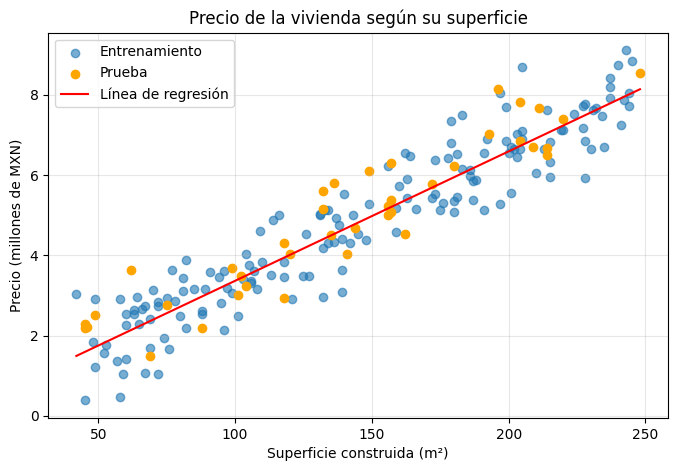

In [2]:
# =====================================================
# EJERCICIO A: REGRESIÓN LINEAL (precios de vivienda)
# =====================================================
# --- 1) Datos simulados: 200 viviendas ---
rng = np.random.default_rng(seed)
n = 200
superficie = rng.uniform(40, 250, n)                       # superficie construida (m²)
precio = 0.5 + 0.030 * superficie + rng.normal(0, 0.7, n)  # precio (millones de MXN)
df = pd.DataFrame({"superficie_m2": superficie.round(0), "precio_mdp": precio.round(2)})

# --- 2) Inspección: dimensiones, tipos, nulos, duplicados y outliers (IQR) ---
print("shape:", df.shape)
df.info()
print(df.describe())
print("Nulos:\n", df.isnull().sum().to_string())
print("Duplicados:", df.duplicated().sum())
for col in df.columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"Outliers (IQR) en {col}: {out}")

# --- 3) Matriz X (2D) y variable objetivo y (continua) ---
X = df[["superficie_m2"]]
y = df["precio_mdp"]

# --- 4) División 80/20, entrenamiento y predicción ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed)
modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# --- 5) Métricas ---
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Pendiente (coef_):", round(modelo.coef_[0], 4))
print("Intercepto:", round(modelo.intercept_, 4))
print(f"MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

# --- 6) Gráfico: dispersión + línea de regresión ---
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.6, label="Entrenamiento")
plt.scatter(X_test, y_test, color="orange", label="Prueba")
xs = pd.DataFrame({"superficie_m2": np.linspace(X.min().iloc[0], X.max().iloc[0], 100)})
plt.plot(xs, modelo.predict(xs), color="red", label="Línea de regresión")
plt.title("Precio de la vivienda según su superficie")
plt.xlabel("Superficie construida (m²)")
plt.ylabel("Precio (millones de MXN)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretación A:** la pendiente (≈0.0323) indica que cada m² adicional se asocia con ≈0.032 millones de MXN más. RMSE ≈ 0.71 millones y R² = 0.855. Limitaciones: una sola variable, relación lineal, sensibilidad a outliers, no extrapolar y datos simulados.

## Ejercicio B: clustering KMeans (segmentación de clientes)
Escalamiento, selección de k con codo y Silhouette, centroides en escala original y gráfico.

shape: (200, 2)
Nulos:
 ingreso_anual_miles    0
puntaje_gasto          0
Duplicados: 5
       ingreso_anual_miles  puntaje_gasto
count           200.000000     200.000000
mean             57.605000      49.830000
std              28.676658      29.145125
min              13.000000       1.000000
25%              31.000000      22.000000
50%              60.000000      49.500000
75%              85.000000      78.000000
max             108.000000      99.000000
k | Inercia | Silhouette
2 | 213.14 | 0.480
3 | 106.03 | 0.585
4 | 27.67 | 0.736
5 | 24.39 | 0.641
6 | 20.98 | 0.568
   ingreso_anual_miles  puntaje_gasto  tamaño
0                 29.6           75.3      50
1                 84.0           20.0      50
2                 30.7           23.5      50
3                 86.1           80.6      50


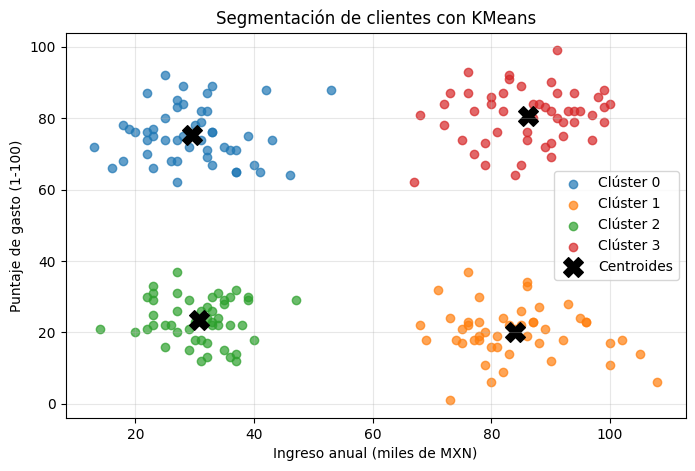

In [3]:
# =====================================================
# EJERCICIO B: CLUSTERING KMEANS (segmentación de clientes, estilo Mall Customers)
# =====================================================
# --- 1) Datos simulados: 200 clientes (ingreso anual en miles de MXN y puntaje de gasto 1-100) ---
rng = np.random.default_rng(seed)
segmentos = [(30, 25), (30, 75), (85, 20), (85, 80)]       # (ingreso medio, puntaje medio)
filas = [pd.DataFrame({"ingreso_anual_miles": rng.normal(i, 8, 50),
                       "puntaje_gasto": rng.normal(p, 8, 50)}) for i, p in segmentos]
clientes = pd.concat(filas, ignore_index=True)
clientes["ingreso_anual_miles"] = clientes["ingreso_anual_miles"].clip(lower=10).round(0)
clientes["puntaje_gasto"] = clientes["puntaje_gasto"].clip(1, 99).round(0)

# --- 2) Preprocesamiento: nulos, duplicados y escalamiento ---
print("shape:", clientes.shape)
print("Nulos:\n", clientes.isnull().sum().to_string())
print("Duplicados:", clientes.duplicated().sum())
print(clientes.describe())
X_c = clientes[["ingreso_anual_miles", "puntaje_gasto"]]
scaler = StandardScaler()
X_esc = scaler.fit_transform(X_c)                          # media 0 y desviación 1

# --- 3) Selección de k: inercia (codo) y Silhouette ---
print("k | Inercia | Silhouette")
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X_esc)
    print(f"{k} | {km.inertia_:.2f} | {silhouette_score(X_esc, km.labels_):.3f}")

# --- 4) Modelo final y perfilamiento ---
k_final = 4
kmeans = KMeans(n_clusters=k_final, random_state=seed, n_init=10)
clientes["cluster"] = kmeans.fit_predict(X_esc)
centros = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=["ingreso_anual_miles", "puntaje_gasto"]).round(1)
centros["tamaño"] = clientes["cluster"].value_counts().sort_index().values
print(centros)

# --- 5) Gráfico: clústeres coloreados + centroides ---
plt.figure(figsize=(8, 5))
for c in range(k_final):
    d = clientes[clientes["cluster"] == c]
    plt.scatter(d["ingreso_anual_miles"], d["puntaje_gasto"], alpha=0.7, label=f"Clúster {c}")
plt.scatter(centros["ingreso_anual_miles"], centros["puntaje_gasto"], color="black",
            marker="X", s=200, label="Centroides")
plt.title("Segmentación de clientes con KMeans")
plt.xlabel("Ingreso anual (miles de MXN)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretación B:** k = 4 (mayor Silhouette, 0.736, y codo de la inercia). Grupos: ingreso bajo y gasto alto; ingreso alto y gasto bajo; ingreso bajo y gasto bajo; ingreso alto y gasto alto (premium).

## Sección 4: conclusión de negocio y reflexión
- **Regresión:** usar ≈$32,300 por m² como referencia de precios y el RMSE (≈$710,000) como margen de negociación.
- **Clustering:** estrategias por segmento: lealtad premium, activación del segmento de ingreso alto y gasto bajo, promociones por volumen y ofertas básicas de bajo costo.
- **Limitaciones:** datos simulados, 40 datos de prueba, modelos simples y duplicados conservados.
- **Reflexión:** ética (LFPDPPP, sesgos, supervisión humana), calidad de datos y reproducibilidad (semilla 42).